# AutoSchema: a step-by-step library walkthrough

Bismillah. This notebook takes a flat CSV through profiling, SQL table inference, queries, verification, and visualization.

**You will learn to:**

1. Import the library and inspect a CSV.
2. Convert data with a domain primary key.
3. Read summary statistics and inspect inferred relationships.
4. Query the reconstructed dataset and chart the processing results.
5. Use a pandas DataFrame or your own CSV.

The included retail sample is **synthetic**: 4,800 rows and 23 columns covering orders, customers, products, warehouses, and stock locations. It contains no real customer data. All examples run locally with SQLite; DuckDB is optional.

Run the cells from top to bottom, or choose **Restart Kernel and Run All**. Each run creates a fresh directory and never overwrites an earlier conversion.


## Before you start

From the repository root, run these commands in your terminal:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install --upgrade pip
python -m pip install -e '.[notebook]'
python -m jupyter lab notebooks/autoschema_walkthrough.ipynb
```

You can also open the notebook in VS Code and select the project's `.venv` Python interpreter. If an import fails, install the missing package in that same interpreter and restart the kernel. AutoSchema itself needs pandas; Jupyter and Matplotlib are used for this tutorial.

The notebook finds the repository from its current working directory, so launch Jupyter from the repository root or `notebooks/` directory.


## 1. Import the library

`convert_csv()` reads a file. `convert_dataframe()` accepts data already in pandas. Both return a `ConversionResult` containing paths, statistics, and read-only query methods.


In [1]:
import os
import sys
from collections import Counter
from html import escape
from pathlib import Path
from uuid import uuid4

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "autoschema" / "__init__.py").is_file()
     and (path / "pyproject.toml").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Launch Jupyter from the autoschema_repo folder or its notebooks/ folder.")

# Import the package installed in this kernel's Python environment.

import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from autoschema import __version__, convert_csv, convert_dataframe, load_result

print(f"AutoSchema {__version__} | Python {sys.version.split()[0]}")


Matplotlib is building the font cache; this may take a moment.


AutoSchema 0.3.0 | Python 3.9.6


## 2. Inspect the input CSV

Read strings first so identifiers, postcodes with leading zeros, literal `NA`, and empty fields retain their meaning. The library performs its own conservative numeric inference during conversion.


In [2]:
csv_path = ROOT / "data" / "retail_complex.csv"
if not csv_path.is_file():
    raise FileNotFoundError("Generate the sample with: python3 examples/generate_retail.py")

source = pd.read_csv(csv_path, dtype=str, keep_default_na=False)
print(f"Rows: {len(source):,} | Columns: {len(source.columns)}")
print(f"Blank cells: {int((source == '').sum().sum()):,}")
display(source.head(3))


Rows: 4,800 | Columns: 23
Blank cells: 1,380


,order_id,order_date,order_status,sales_channel,customer_id,customer_name,customer_city,customer_segment,line_number,product_id,...,unit_price,warehouse_id,warehouse_name,warehouse_city,warehouse_postcode,bin_location,reorder_point,quantity,discount_percent,delivery_note
0,O000000,2025-03-17,Returned,Web,C0057,Customer 0057,Perth,Trade,1,P034,...,27.08,W3,Distribution centre 3,Perth,6000,F-11,34,6,0,Customer's side door
1,O000000,2025-03-17,Returned,Web,C0057,Customer 0057,Perth,Trade,2,P048,...,29.70,W3,Distribution centre 3,Perth,6000,G-02,39,8,0,Café delivery
2,O000000,2025-03-17,Returned,Web,C0057,Customer 0057,Perth,Trade,3,P012,...,101.17,W1,Distribution centre 1,Sydney,2000,D-07,26,7,0,Café delivery


## 3. Choose where to save results

By default, outputs go into **`results/notebook-runs/`**, which you can inspect in your file explorer. Change `output_root` if you prefer another location. The optional environment variable allows automated notebook checks to use a temporary directory.

`new_output()` adds a unique suffix. Re-running a conversion cell therefore creates a new result instead of hitting the library's overwrite protection.


In [3]:
output_root = Path(os.environ.get("AUTOSCHEMA_NOTEBOOK_OUTPUT", ROOT / "results" / "notebook-runs"))

def new_output(label):
    return output_root / f"{label}-{uuid4().hex[:10]}"


## 4. Convert the CSV into SQL tables

For retail order lines, `(order_id, line_number)` is a domain key: an order can have many lines, but each line number is unique within its order.

The library validates this key, discovers exact dependencies in the observed data, builds dimension tables, and creates a joining view called `dataset`. Default searches consider one- and two-column determinants. SQLite is built into Python.


In [4]:
result = convert_csv(
    csv_path,
    out=new_output("retail"),
    engine="sqlite",
    key_columns=["order_id", "line_number"],
    max_dependency_width=2,
)

stats = result.summary()
print(f"Created {len(result.tables)} physical tables.")
print(f"Exact reconstruction verified: {stats['reconstruction_exact']}")


Created 6 physical tables.
Exact reconstruction verified: True


## 5. Read the summary statistics

`summary()` returns an independent, JSON-serializable dictionary. It includes column profiles, dependencies, key candidates, table sizes, search bounds, stage timings, and validation results.

**Stored cells** means the sum of rows × columns across physical tables, including their keys. It measures repeated values removed. Actual database bytes are reported separately; normalization does not guarantee a smaller file than the CSV.


In [5]:
summary = pd.DataFrame([
    ("Input rows", stats["input_rows"]),
    ("Input columns", stats["input_columns"]),
    ("Physical SQL tables", len(stats["tables"])),
    ("Duplicate rows beyond the first", stats["duplicate_rows"]),
    ("Blank cells", stats["blank_cells"]),
    ("Input cells", stats["input_cells"]),
    ("Stored cells", stats["stored_cells"]),
    ("Stored-cell reduction (%)", stats["cell_reduction_percent"]),
    ("Source CSV bytes", stats["source"]["bytes"]),
    ("Database bytes", stats["database_bytes"]),
    ("Database / CSV size ratio", stats["database_to_csv_ratio"]),
    ("Processing seconds", stats["processing_seconds"]),
    ("Exact reconstruction", stats["reconstruction_exact"]),
], columns=["Metric", "Value"])
display(summary)


,Metric,Value
0,Input rows,4800
1,Input columns,23
2,Physical SQL tables,6
3,Duplicate rows beyond the first,0
4,Blank cells,1380
5,Input cells,110400
6,Stored cells,44956
7,Stored-cell reduction (%),59.28
8,Source CSV bytes,827266
9,Database bytes,458752


In [6]:
profiles = pd.DataFrame(stats["column_profiles"])
display(profiles)


,name,sql_type,distinct,distinct_percent,blank_count,min,max,mean
0,order_id,VARCHAR,1200,25.00,0,NaN,NaN,NaN
1,order_date,VARCHAR,90,1.88,0,NaN,NaN,NaN
2,order_status,VARCHAR,4,0.08,0,NaN,NaN,NaN
3,sales_channel,VARCHAR,3,0.06,0,NaN,NaN,NaN
4,customer_id,VARCHAR,120,2.50,0,NaN,NaN,NaN
5,customer_name,VARCHAR,120,2.50,0,NaN,NaN,NaN
6,customer_city,VARCHAR,6,0.12,0,NaN,NaN,NaN
7,customer_segment,VARCHAR,3,0.06,0,NaN,NaN,NaN
8,line_number,BIGINT,4,0.08,0,1.0,4.0,2.500000
9,product_id,VARCHAR,60,1.25,0,NaN,NaN,NaN


Numeric columns have `min`, `mean`, and `max` values. Those fields are empty for text columns. `blank_count` counts empty strings. For example, a postcode such as `0300` remains text so the leading zero survives.

## 6. Inspect the inferred tables and keys

The fact table `records` contains row-level values and foreign keys. Dimension tables hold repeated attributes. A multi-column key works as a group, rather than as separate independent keys.


In [7]:
tables = pd.DataFrame([
    {
        "table": table["name"],
        "rows": table["rows"],
        "columns": len(table["columns"]),
        "primary_key": ", ".join(table["primary_key"]) or "None found",
        "foreign_keys": "; ".join(
            f"{', '.join(fk['columns'])} → {fk['references']}"
            for fk in table["foreign_keys"]
        ),
    }
    for table in stats["tables"]
])
display(tables)


,table,rows,columns,primary_key,foreign_keys
0,dim_product_id,60,5,product_id,
1,dim_warehouse_id,4,4,warehouse_id,
2,dim_customer_id,120,4,customer_id,
3,dim_order_id,1200,4,order_id,
4,dim_product_id_warehouse_id,240,4,"product_id, warehouse_id",
5,records,4800,8,"order_id, line_number",product_id → dim_product_id; warehouse_id → di...


In [8]:
dependencies = pd.DataFrame([
    {
        "determinant": " + ".join(dependency["keys"]),
        "determines": ", ".join(dependency["attributes"]),
        "distinct_keys": dependency["distinct_keys"],
    }
    for dependency in stats["dependencies"]
])
display(dependencies)

print("Chosen dimensions with composite keys:")
for dimension in stats["dimensions"]:
    if len(dimension["keys"]) > 1:
        print(f"  {dimension['keys']} → {dimension['attributes']}")


,determinant,determines,distinct_keys
0,order_id,"order_date, order_status, sales_channel, custo...",1200
1,customer_id,"customer_name, customer_city, customer_segment",120
2,product_id,"product_name, category, brand, unit_price",60
3,warehouse_id,"warehouse_name, warehouse_city, warehouse_post...",4
4,customer_name,"customer_id, customer_city, customer_segment",120
5,product_name,"product_id, category, brand, unit_price",60
6,warehouse_name,"warehouse_id, warehouse_city, warehouse_postcode",4
7,warehouse_city,"warehouse_id, warehouse_name, warehouse_postcode",4
8,warehouse_postcode,"warehouse_id, warehouse_name, warehouse_city",4
9,product_id + warehouse_id,"bin_location, reorder_point",240


Chosen dimensions with composite keys:
  ['product_id', 'warehouse_id'] → ['bin_location', 'reorder_point']


For this sample, `customer_id` determines customer details, while `(product_id, warehouse_id)` determines the inventory location and reorder point. These relationships were observed in this file; they still need domain review before use with future data.

## 7. Read tables as pandas DataFrames

Use `result.tables` to discover physical table names. `read_table()` defaults to the reconstructed `dataset` view, containing all original columns. Reading that view loads the returned data into memory.


In [9]:
print("Physical tables:", result.tables)
customers = result.read_table("dim_customer_id")
records = result.read_table("records")
reconstructed = result.read_table()  # equivalent to read_table("dataset")

display(customers.head(5))
display(records.head(3))
print(f"Reconstructed dataset: {reconstructed.shape[0]:,} rows × {reconstructed.shape[1]} columns")


Physical tables: ['dim_product_id', 'dim_warehouse_id', 'dim_customer_id', 'dim_order_id', 'dim_product_id_warehouse_id', 'records']


,customer_id,customer_name,customer_city,customer_segment
0,C0057,Customer 0057,Perth,Trade
1,C0084,Customer 0084,Melbourne,Member
2,C0088,Customer 0088,Adelaide,Member
3,C0090,Customer 0090,Melbourne,Member
4,C0010,Customer 0010,Adelaide,Member


,order_id,customer_id,line_number,product_id,warehouse_id,quantity,discount_percent,delivery_note
0,O000000,C0057,1,P034,W3,6,0,Customer's side door
1,O000000,C0057,2,P048,W3,8,0,Café delivery
2,O000000,C0057,3,P012,W1,7,0,Café delivery


Reconstructed dataset: 4,800 rows × 23 columns


## 8. Query the reconstructed dataset with SQL

`query()` opens a read-only connection and returns a DataFrame. Querying `dataset` lets you use the original column names without manually joining dimensions.


In [10]:
sales = result.query("""
    SELECT category,
           SUM(quantity) AS units,
           ROUND(SUM(quantity * CAST(unit_price AS DOUBLE)), 2) AS gross_sales
    FROM dataset
    GROUP BY category
    ORDER BY gross_sales DESC
""")
display(sales)


,category,units,gross_sales
0,Kitchen,6457,649376.99
1,Home,4180,488950.51
2,Outdoors,3617,480370.94
3,Garden,4113,464457.15
4,Office,3269,428401.83


`unit_price` is explicitly cast for arithmetic because fixed decimal text such as `12.50` can remain text to preserve its formatting. Here, **gross sales** means quantity × listed unit price, before discounts or returns. This illustrative query uses floating-point arithmetic; use a deliberate currency representation for accounting.

For values supplied by a user, pass SQL parameters rather than assembling strings:


In [11]:
selected_customer = customers.iloc[0]["customer_id"]
customer_orders = result.query(
    """SELECT order_id, line_number, product_id, quantity
       FROM dataset
       WHERE customer_id = ?
       ORDER BY order_id, line_number
       LIMIT 5""",
    parameters=[selected_customer],
)
display(customer_orders)


,order_id,line_number,product_id,quantity
0,O000000,1,P034,6
1,O000000,2,P048,8
2,O000000,3,P012,7
3,O000000,4,P049,1
4,O000110,1,P017,2


## 9. Visualize what happened

These charts answer three different questions: how many repeated cells were removed, how much space the database actually occupies, and which processing stages took the most time. Database size excludes the extra SQL and CSV export files.


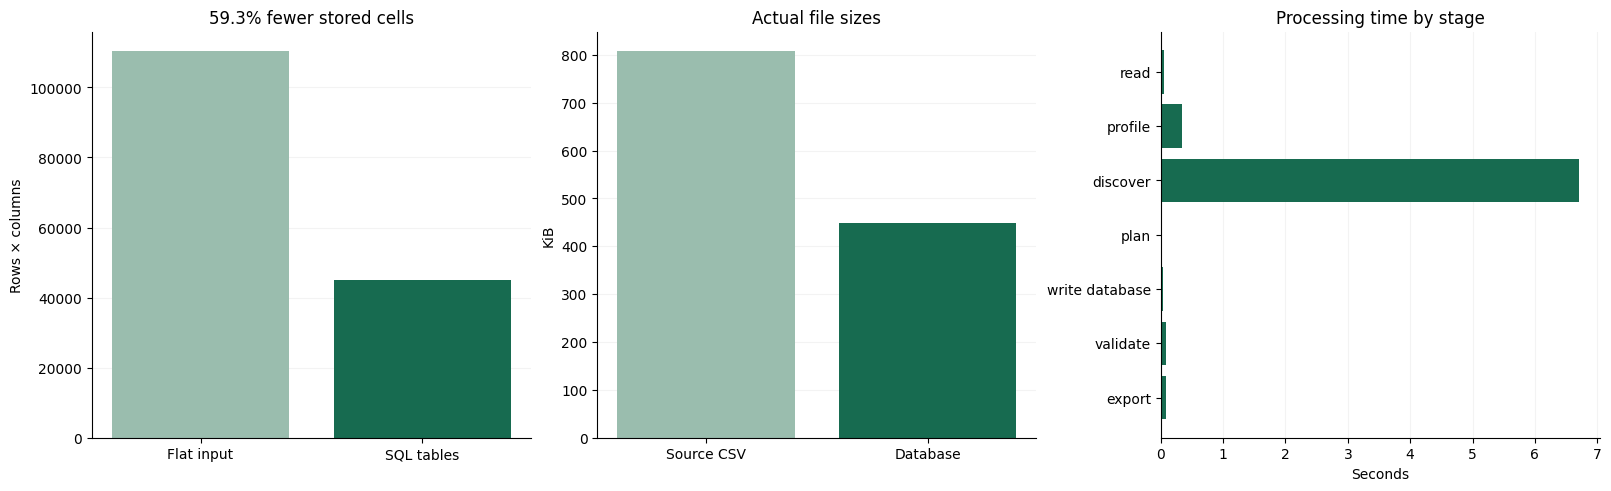

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
colors = ["#9abdae", "#176b50"]

axes[0].bar(["Flat input", "SQL tables"], [stats["input_cells"], stats["stored_cells"]], color=colors)
axes[0].set_title(f"{stats['cell_reduction_percent']:.1f}% fewer stored cells")
axes[0].set_ylabel("Rows × columns")

axes[1].bar(["Source CSV", "Database"], [stats["source"]["bytes"] / 1024, stats["database_bytes"] / 1024], color=colors)
axes[1].set_title("Actual file sizes")
axes[1].set_ylabel("KiB")

timings = pd.Series(stats["timings_seconds"])
axes[2].barh(timings.index.str.replace("_", " "), timings.values, color="#176b50")
axes[2].invert_yaxis()
axes[2].set_title("Processing time by stage")
axes[2].set_xlabel("Seconds")

for axis in axes:
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis="y" if axis is not axes[2] else "x", alpha=0.15)
    axis.set_axisbelow(True)

plt.show()


## 10. View the visual processing report

Each conversion also writes **`report.html`** with the pipeline, table relationships, searchable column profiles, and inference limits. The preview below is embedded in this notebook, so it remains viewable without the generated files. Download links are hidden in this embedded preview; open the standalone report to use its links to SQL and CSV exports.

After running the notebook, evaluate `result.report_path` in a new cell to see the standalone report's full path. Jupyter may require you to trust the notebook before showing embedded HTML.


In [13]:
report_html = result.report_path.read_text(encoding="utf-8")
preview = report_html.replace(
    "</head>",
    "<style>.files { display: none; }</style></head>",
)
display(HTML(
    '<iframe title="AutoSchema processing report" '
    'sandbox="allow-scripts" '
    'style="width:100%;height:720px;border:1px solid #d6e2df;border-radius:12px" '
    f'srcdoc="{escape(preview, quote=True)}"></iframe>'
))


/Users/adhni/Desktop/autoschema_repo/.venv/lib/python3.9/site-packages/IPython/core/display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## 11. Verify reconstruction and inspect the exports

The library already verifies the result before returning it. Here, we also compare the reconstructed sample with the original CSV. Comparing multisets preserves duplicate counts and avoids depending on SQL row order.

For this sample, numeric values are converted back to strings for comparison. This check is intentionally tailored to the included sample; the library's internal validation compares the normalized typed input.


In [14]:
assert stats["reconstruction_exact"] is True
assert list(reconstructed.columns) == list(source.columns)
assert Counter(reconstructed.astype(str).itertuples(index=False, name=None)) == Counter(
    source.itertuples(index=False, name=None)
)
print("Alhamdulillah: every sample row was reconstructed, including duplicate multiplicities.")

exports = pd.DataFrame([
    {"file": path.name, "bytes": path.stat().st_size}
    for path in sorted(result.output_dir.iterdir()) if path.is_file()
])
display(exports)


Alhamdulillah: every sample row was reconstructed, including duplicate multiplicities.


,file,bytes
0,dataset.sql,575552
1,dataset.sqlite,458752
2,dim_customer_id.csv,4223
3,dim_order_id.csv,40683
4,dim_product_id.csv,2278
5,dim_product_id_warehouse_id.csv,3860
6,dim_warehouse_id.csv,214
7,records.csv,205236
8,report.html,15705
9,schema.json,14967


### Reopen a saved conversion

`load_result()` lets another Python session use the saved database and statistics without rerunning inference. It also supports the older 0.2 reports.

In [15]:
reopened = load_result(result.output_dir)
assert reopened.summary() == result.summary()
display(reopened.query("SELECT COUNT(*) AS reconstructed_rows FROM dataset"))

,reconstructed_rows
0,4800


`dataset.sqlite` contains the real SQL tables. `schema.sql` contains definitions only. `dataset.sql` contains definitions **and data inserts**. `records.csv` and `dim_*.csv` are readable copies of the physical tables. `schema.json` contains the complete statistics.

## 12. Convert a DataFrame instead of a CSV

Use this when you have already filtered, cleaned, or joined data in pandas. The input DataFrame is not changed. Missing values become empty strings; arbitrary pandas dtypes are not preserved.


In [16]:
frame = pd.DataFrame({
    "row_id": range(1, 9),
    "customer_id": ["C01", "C02"] * 4,
    "customer_name": ["Amina", "Yusuf"] * 4,
    "city": ["Melbourne", "Sydney"] * 4,
    "quantity": [1, 3, 2, 1, 4, 2, 3, 5],
})
before = frame.copy(deep=True)

frame_result = convert_dataframe(
    frame,
    out=new_output("dataframe"),
    key_columns=["row_id"],
)
pd.testing.assert_frame_equal(frame, before)
print("Input DataFrame unchanged.")
print("Table rows:", frame_result.summary()["table_rows"])
display(frame_result.read_table())


Input DataFrame unchanged.
Table rows: {'dim_customer_id': 2, 'records': 8}


,row_id,customer_id,customer_name,city,quantity
0,1,C01,Amina,Melbourne,1
1,2,C02,Yusuf,Sydney,3
2,3,C01,Amina,Melbourne,2
3,4,C02,Yusuf,Sydney,1
4,5,C01,Amina,Melbourne,4
5,6,C02,Yusuf,Sydney,2
6,7,C01,Amina,Melbourne,3
7,8,C02,Yusuf,Sydney,5


## 13. Adapt this to your own dataset

Set `your_csv` to an existing CSV and run the conversion. Leave it as `None` to keep this cell optional. Start with automatic key discovery, then inspect the result and set a domain key with `key_columns=[...]` on a fresh run if needed. The SQL queries above use retail column names and should be adapted to your data.

For wider datasets, the default search is bounded to 30 determinant columns and 2,000 candidates per dependency/key search. Increasing widths and budgets costs CPU and memory. The entire input must currently fit in RAM.


In [17]:
your_csv = None  # Example: ROOT / "data" / "my_dataset.csv"

if your_csv is not None:
    your_result = convert_csv(
        your_csv,
        out=new_output("my-data"),
        engine="sqlite",
        # key_columns=["transaction_id"],
        # delimiter=";",                 # for semicolon-separated input
        max_dependency_width=2,           # increase to 3 deliberately
        max_key_width=2,
        max_candidate_columns=30,
        max_checks=2000,
    )
    display(pd.DataFrame(your_result.summary()["tables"]))
else:
    print("Set your_csv to try your own file, insyallah.")


Set your_csv to try your own file, insyallah.


## 14. Optional: use DuckDB

SQLite needs no extra database package. To use DuckDB, install it into the active notebook environment with `%pip install duckdb`, restart the kernel if needed, and enable this example. It performs the same reconstruction check and writes a `dataset.duckdb` file.


In [18]:
run_duckdb = False

if run_duckdb:
    duckdb_result = convert_csv(
        csv_path,
        out=new_output("retail-duckdb"),
        engine="duckdb",
        key_columns=["order_id", "line_number"],
    )
    print("DuckDB reconstruction:", duckdb_result.summary()["reconstruction_exact"])
else:
    print("Optional DuckDB example skipped; the SQLite walkthrough is complete.")


Optional DuckDB example skipped; the SQLite walkthrough is complete.


## What to check before relying on a result

- Review inferred dependencies as observed patterns, rather than proven domain rules. Conflicting mappings are not silently repaired.
- Use `key_columns` when you know the true primary key. Accidentally unique measurements can otherwise look like keys.
- Read `stats["warnings"]` and `stats["search"]` to see inference limits and any reached budgets.
- Compare actual bytes separately from stored-cell reduction. A database can be larger than its source CSV.
- Keep the source CSV. The reconstruction preserves normalized values and duplicate counts, while row order and original CSV quoting are unspecified.

You can also run the same library from your terminal:

```bash
python3 -m autoschema data/retail_complex.csv --out results/my-next-run
```

Further API details and limitations are in the repository's `README.md`.


In [19]:
print("Warnings from this run:")
for warning in stats["warnings"]:
    print("•", warning)

display(pd.DataFrame([stats["search"]]))


Warnings from this run:
• Dependencies describe this input; review inferred relationships before using them with future data.
• Processing and exact reconstruction validation load data into memory; this is not a streaming converter.


,max_dependency_width,max_key_width,max_candidate_columns,max_checks,determinant_columns,dependency_checks,key_checks,dependency_budget_reached,key_budget_reached
0,2,2,30,2000,"[order_id, customer_id, product_id, warehouse_...",276,1,False,False
